# Chest X-Ray Pneumonia — Model Development

Compare a majority baseline, logistic regression, linear SVM and random forest on identical prepared features and grouped folds. This adapts the [model-development reference](https://github.com/tejuuu-7774/Inventory-demand-forecasting/blob/main/Notebooks/03_model_development.ipynb) to binary image classification. Run notebooks 01 and 02 first. No deep-learning training is included.

## 1. Import model libraries

Use scikit-learn pipelines, metrics and group CV; save real predictions and fitted models.

In [1]:
import sys, json, hashlib, re, importlib.util
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, Image as NotebookImage
SEED = 42
CLASSES = {'NORMAL': 0, 'PNEUMONIA': 1}
IN_COLAB = importlib.util.find_spec('google.colab') is not None
print('Environment:', 'Google Colab' if IN_COLAB else 'Local Python')

import argparse
import hashlib
import importlib.metadata
import json
import platform
import re
import time
from pathlib import Path

import joblib
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score,
    precision_score, recall_score, roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay,
    precision_recall_curve)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

SEED = 42
CLASSES = {'NORMAL': 0, 'PNEUMONIA': 1}

Environment: Local Python


## 2. Find the prepared-data and output folders

All stages use one project folder. Colab stages share outputs through Drive.

In [2]:
# Use the SAME PROJECT_ROOT in all three notebooks.
# Colab: put the extracted images under MyDrive/chest_xray before running.
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/drive/MyDrive/Chest-Xray-Pneumonia-ML')
    DATA_ROOT = Path('/content/drive/MyDrive/chest_xray')
else:
    PROJECT_ROOT = Path.cwd()
    if PROJECT_ROOT.name == 'Notebooks': PROJECT_ROOT = PROJECT_ROOT.parent
    DATA_ROOT = Path.home() / 'Downloads/chest_xray'
OUTPUT = PROJECT_ROOT
for folder in ('Datasets/processed','results','report/figures','models'):
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)
PROCESSED_DIR = PROJECT_ROOT / 'Datasets/processed'
FIGURE_DIR = PROJECT_ROOT / 'report/figures'
print('Project folder:', PROJECT_ROOT)
print('Raw data folder:', DATA_ROOT)

Project folder: /Users/ravichandrashinde/Chest-Xray-Pneumonia-ML
Raw data folder: /Users/ravichandrashinde/Downloads/chest_xray


## 3. Load prepared features and settings

Load exactly the row order saved by notebook 02. Retained metadata controls splitting, not prediction.

In [3]:
config=json.loads((PROCESSED_DIR/'phase1_config.json').read_text())
selected=pd.read_csv(PROCESSED_DIR/'retained_manifest.csv',keep_default_na=False)
cache=np.load(PROCESSED_DIR/'features.npz')
x=cache['X']
assert np.array_equal(cache['y'],selected.target)
assert config['seed']==SEED and config['n_folds']==3
out=OUTPUT
print('Feature matrix:',x.shape)
print(json.dumps(config,indent=2))

Feature matrix: (5371, 1799)
{
  "seed": 42,
  "image_size": [
    64,
    64
  ],
  "n_folds": 3,
  "positive_class": "PNEUMONIA",
  "selection_metric": "balanced_accuracy",
  "feature_version": 1
}


## 4. Define the evaluation metrics

Balanced accuracy selects models. Also measure recall, specificity, precision, F1, ROC-AUC and average precision. Bootstrap groups, not independent images, for conditional uncertainty intervals.

In [4]:
def save_json(value, path):
    Path(path).write_text(json.dumps(value, indent=2, default=lambda v: v.item() if isinstance(v, np.generic) else str(v)))


def scores(y, score, pred):
    tn, fp, fn, tp = confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(accuracy=accuracy_score(y,pred), balanced_accuracy=balanced_accuracy_score(y,pred),
        precision=precision_score(y,pred,zero_division=0), recall=recall_score(y,pred,zero_division=0),
        specificity=tn/(tn+fp), f1=f1_score(y,pred,zero_division=0),
        roc_auc=roc_auc_score(y,score), average_precision=average_precision_score(y,score),
        tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp))


def group_bootstrap(y, score, pred, groups, n=1000):
    rng = np.random.default_rng(SEED)
    unique = np.unique(groups)
    ids = {g: np.flatnonzero(groups==g) for g in unique}
    rows = []
    for _ in range(n):
        idx = np.concatenate([ids[g] for g in rng.choice(unique,len(unique),replace=True)])
        if len(np.unique(y[idx])) == 2:
            rows.append(scores(y[idx],score[idx],pred[idx]))
    return {k: {'lower':float(np.quantile([r[k] for r in rows],.025)),
                'upper':float(np.quantile([r[k] for r in rows],.975))}
            for k in ('balanced_accuracy','recall','specificity','f1','roc_auc','average_precision')}

## 5. Set up development data and grouped folds

Keep the final test aside. Verify group disjointness and save exact validation-fold assignments.

In [5]:
dev = selected.partition.eq('development').to_numpy()
xd, xt = x[dev], x[~dev]
yd, yt = selected.target.to_numpy()[dev], selected.target.to_numpy()[~dev]
gd, gt = selected.group.to_numpy()[dev], selected.group.to_numpy()[~dev]
assert not set(gd) & set(gt), 'Development/test group leakage'
cv = list(StratifiedGroupKFold(3,shuffle=True,random_state=SEED).split(xd,yd,gd))
for tr, va in cv:
    assert not set(gd[tr]) & set(gd[va])
    assert len(np.unique(yd[va])) == 2
fold_assignment = np.zeros(len(yd),dtype=int)
for f, (_, va) in enumerate(cv): fold_assignment[va] = f
selected.loc[dev,['path','target','group']].assign(cv_fold=fold_assignment).to_csv(out / 'results/cv_folds.csv',index=False)

## 6. Define the baseline and three ML models

Logistic regression uses class-weighted L2 log loss; linear SVM uses a regularized squared hinge loss; the forest averages 200 trees. Smaller C means stronger regularization. Scaling is learned within each Pipeline fit. Class weights address imbalance.

In [6]:
candidates = {
    'majority_baseline': (DummyClassifier(strategy='most_frequent'), {}),
    'logistic_regression': (Pipeline([('scale',StandardScaler()),('model',LogisticRegression(class_weight='balanced',max_iter=3000,random_state=SEED))]), {'model__C':[.01,.1,1.]}),
    'linear_svm': (Pipeline([('scale',StandardScaler()),('model',LinearSVC(class_weight='balanced',dual='auto',max_iter=10000,random_state=SEED))]), {'model__C':[.001,.01,.1]}),
    'random_forest': (RandomForestClassifier(n_estimators=200,class_weight='balanced',max_features='sqrt',n_jobs=2,random_state=SEED), {'min_samples_leaf':[2,5]}),
}

## 7. Train and tune using development CV

Search only the fixed candidate settings. Rank by mean balanced accuracy. Full search results include fold variation, training scores, ROC-AUC and recall.

In [7]:
rows, fitted = [], {}
for name, (estimator, grid) in candidates.items():
    print('Training',name,flush=True)
    start = time.monotonic()
    search = GridSearchCV(estimator,grid,scoring={'balanced_accuracy':'balanced_accuracy','roc_auc':'roc_auc','recall':'recall'},
        refit='balanced_accuracy',cv=cv,n_jobs=1,return_train_score=True,error_score='raise')
    search.fit(xd,yd)
    pd.DataFrame(search.cv_results_).to_csv(out / f'results/cv_{name}.csv',index=False)
    best = search.best_index_
    rows.append(dict(model=name,cv_balanced_accuracy=search.best_score_,
        cv_std=search.cv_results_['std_test_balanced_accuracy'][best],
        cv_roc_auc=search.cv_results_['mean_test_roc_auc'][best],
        train_balanced_accuracy=search.cv_results_['mean_train_balanced_accuracy'][best],
        best_params=json.dumps(search.best_params_),seconds=time.monotonic()-start))
    fitted[name] = search.best_estimator_

Training majority_baseline
Training logistic_regression
Training linear_svm
Training random_forest


## 8. Compare models and select the winner

The majority baseline shows the effect of imbalance. Training–validation gaps flag overfitting. The test never ranks models.

In [8]:
comparison = pd.DataFrame(rows).sort_values('cv_balanced_accuracy',ascending=False)
comparison.to_csv(out / 'results/model_comparison_cv.csv',index=False)

display(comparison)

,model,cv_balanced_accuracy,cv_std,cv_roc_auc,train_balanced_accuracy,best_params,seconds
1,logistic_regression,0.967973,0.003524,0.994830,0.993894,"{""model__C"": 0.01}",1.837122
2,linear_svm,0.963630,0.002903,0.992657,0.988794,"{""model__C"": 0.001}",8.848137
3,random_forest,0.933707,0.007643,0.985756,0.992040,"{""min_samples_leaf"": 5}",30.212075
0,majority_baseline,0.500000,0.000000,0.500000,0.500000,{},0.026474


## 9. Choose a decision threshold from development predictions

OOF predictions select an F1 operating point. Hyperparameters were already selected on these folds, so development estimates are selection-biased and are not nested CV. This is not a clinically validated threshold. SVM and logistic decision scores are not calibrated probabilities.

In [9]:
winner = comparison.iloc[0].model
model = fitted[winner]
method = 'decision_function' if hasattr(model,'decision_function') else 'predict_proba'
oof = cross_val_predict(clone(model),xd,yd,cv=cv,method=method,n_jobs=1)
if oof.ndim == 2: oof = oof[:,1]
default_threshold = 0. if method == 'decision_function' else .5
precision, recall, thresholds = precision_recall_curve(yd,oof)
f1 = 2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
threshold = float(thresholds[np.argmax(f1)])
pd.DataFrame({'target':yd,'score':oof,'group':gd}).to_csv(out / 'results/development_oof_predictions.csv',index=False)

print('Selected model:',winner,'OOF F1 threshold:',threshold)

Selected model: logistic_regression OOF F1 threshold: -0.27093224748002775


## 10. Evaluate the fixed final model on test

All choices are now fixed. Report both the default and declared OOF threshold; do not replace the latter after inspecting test performance. Save group-bootstrap intervals, predictions and the fitted pipeline.

In [10]:
raw = getattr(model,method)(xt)
if raw.ndim == 2: raw = raw[:,1]
pred = (raw>=threshold).astype(int)
default_pred = model.predict(xt)
result = dict(selected_model=winner, selection_metric='3-fold grouped CV balanced accuracy',
    development_images=len(yd),test_images=len(yt),score_type=method,
    default_threshold=default_threshold, f1_threshold_from_development_oof=threshold,
    threshold_caveat='OOF threshold is selected after hyperparameter tuning; development estimates are selection-biased, not nested CV. Test untouched until all choices fixed.',
    test_default=scores(yt,raw,default_pred),test_oof_threshold=scores(yt,raw,pred),
    bootstrap_95_ci=group_bootstrap(yt,raw,pred,gt),
    classification_report=classification_report(yt,pred,target_names=list(CLASSES),output_dict=True,zero_division=0))
save_json(result,out / 'results/final_evaluation.json')
selected.loc[~dev,['path','target','group']].assign(score=raw,prediction=pred,default_prediction=default_pred).to_csv(out / 'results/test_predictions.csv',index=False)
joblib.dump({'model':model,'threshold':threshold,'score_method':method,'classes':CLASSES,
             'image_size':(64,64),'feature_version':1},out / 'models/best_model.joblib')

print(json.dumps(result,indent=2))

{
  "selected_model": "logistic_regression",
  "selection_metric": "3-fold grouped CV balanced accuracy",
  "development_images": 4753,
  "test_images": 618,
  "score_type": "decision_function",
  "default_threshold": 0.0,
  "f1_threshold_from_development_oof": -0.27093224748002775,
  "threshold_caveat": "OOF threshold is selected after hyperparameter tuning; development estimates are selection-biased, not nested CV. Test untouched until all choices fixed.",
  "test_default": {
    "accuracy": 0.8268608414239482,
    "balanced_accuracy": 0.7736333434007853,
    "precision": 0.7904564315352697,
    "recall": 0.9844961240310077,
    "specificity": 0.5627705627705628,
    "f1": 0.8768699654775605,
    "roc_auc": 0.9628063581551953,
    "average_precision": 0.9770833490371873,
    "tn": 130,
    "fp": 101,
    "fn": 6,
    "tp": 381
  },
  "test_oof_threshold": {
    "accuracy": 0.8203883495145631,
    "balanced_accuracy": 0.7632303097419377,
    "precision": 0.7816326530612245,
    "recal

## 11. Plot the confusion matrix, ROC and precision–recall

False negatives and false positives have different implications. A high AUC does not guarantee good specificity at a chosen threshold.

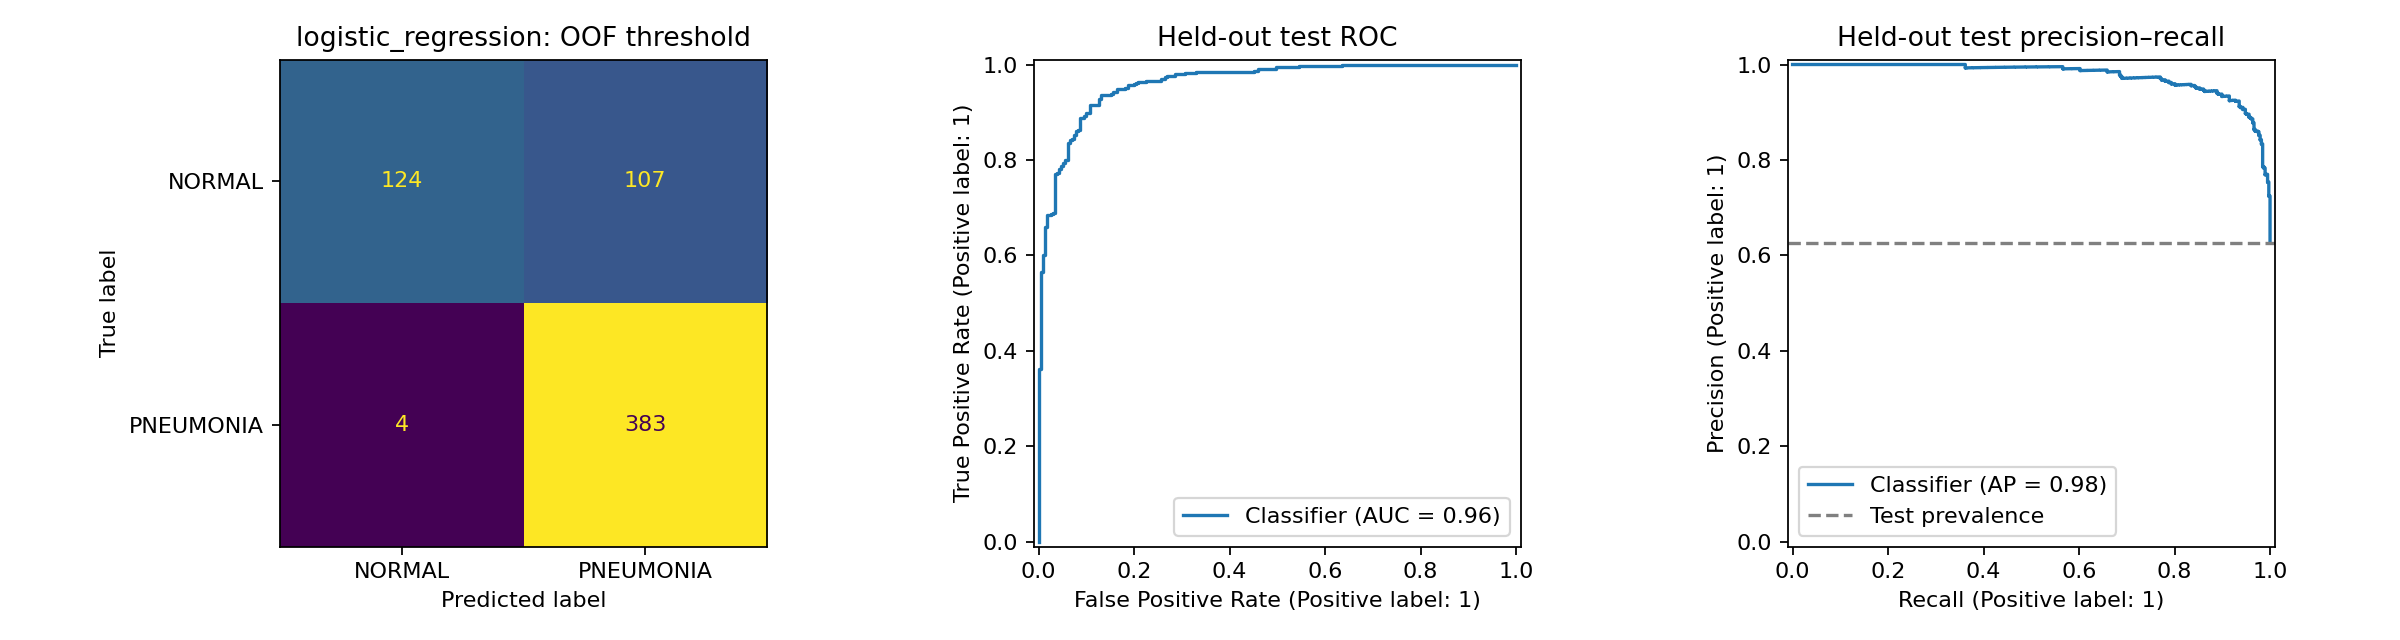

In [11]:
fig, axes = plt.subplots(1,3,figsize=(15,4))
ConfusionMatrixDisplay.from_predictions(yt,pred,display_labels=list(CLASSES),ax=axes[0],colorbar=False)
axes[0].set_title(f'{winner}: OOF threshold')
RocCurveDisplay.from_predictions(yt,raw,ax=axes[1]); axes[1].set_title('Held-out test ROC')
PrecisionRecallDisplay.from_predictions(yt,raw,ax=axes[2]); axes[2].set_title('Held-out test precision–recall')
axes[2].axhline(yt.mean(),ls='--',color='gray',label='Test prevalence'); axes[2].legend()
fig.tight_layout(); fig.savefig(out / 'report/figures/final_evaluation.png',dpi=160); plt.close(fig)

display(NotebookImage(filename=str(FIGURE_DIR/'final_evaluation.png')))

## 12. Compare feature and scaling controls

Keep logistic C=0.1 fixed and compare the same development folds. These controls isolate features/scaling; they are not independently tuned models and never alter the selected model.

In [12]:
ablations=[]
for name, xx, scale in [('texture_intensity_scaled',xd,True),('texture_intensity_unscaled',xd,False),('intensity_only_scaled',xd[:,-25:],True)]:
    est=Pipeline([('scale',StandardScaler() if scale else 'passthrough'),('model',LogisticRegression(C=.1,class_weight='balanced',max_iter=3000,random_state=SEED))])
    vals=[]
    for tr, va in cv:
        est.fit(xx[tr],yd[tr]); vals.append(balanced_accuracy_score(yd[va],est.predict(xx[va])))
    ablations.append(dict(experiment=name,C=.1,cv_balanced_accuracy=float(np.mean(vals)),cv_std=float(np.std(vals))))
pd.DataFrame(ablations).to_csv(out / 'results/feature_scaling_ablation.csv',index=False)

display(pd.DataFrame(ablations))

,experiment,C,cv_balanced_accuracy,cv_std
0,texture_intensity_scaled,0.1,0.966543,0.004162
1,texture_intensity_unscaled,0.1,0.956865,0.007885
2,intensity_only_scaled,0.1,0.886398,0.003112


## 13. Verify the scaling diagnostics

The first-fold training means should be approximately zero after scaling. Validation means can differ. Final model scalers use development only.

In [13]:
tr, va = cv[0]
scaler=StandardScaler().fit(xd[tr])
z=scaler.transform(xd[tr]); zv=scaler.transform(xd[va])
save_json(dict(fold=0,fit_rows=len(tr),validation_rows=len(va),
    max_absolute_training_mean=float(np.abs(z.mean(0)).max()),
    validation_mean_absolute=float(np.abs(zv.mean(0)).mean()),
    constant_features=int((scaler.var_==0).sum())), out / 'results/scaling_diagnostics.json')

print((out/'results/scaling_diagnostics.json').read_text())

{
  "fold": 0,
  "fit_rows": 3168,
  "validation_rows": 1585,
  "max_absolute_training_mean": 6.659398422925733e-06,
  "validation_mean_absolute": 0.03362681344151497,
  "constant_features": 0
}


## 14. Inspect the saved test mistakes

Review a fixed set of test errors descriptively. Do not use these examples to retune the final model.

Test errors: 111


,path,target,group,score,prediction,default_prediction
3,test/NORMAL/IM-0006-0001.jpeg,0,g5235,-0.149290,1,0
4,test/NORMAL/IM-0007-0001.jpeg,0,g5236,-0.069618,1,0
11,test/NORMAL/IM-0015-0001.jpeg,0,g5243,4.517395,1,1
14,test/NORMAL/IM-0019-0001.jpeg,0,g5246,2.251549,1,1
15,test/NORMAL/IM-0021-0001.jpeg,0,g5247,4.653678,1,1
16,test/NORMAL/IM-0022-0001.jpeg,0,g5248,2.920910,1,1
19,test/NORMAL/IM-0027-0001.jpeg,0,g5251,0.829583,1,1
23,test/NORMAL/IM-0031-0001.jpeg,0,g5255,0.394139,1,1


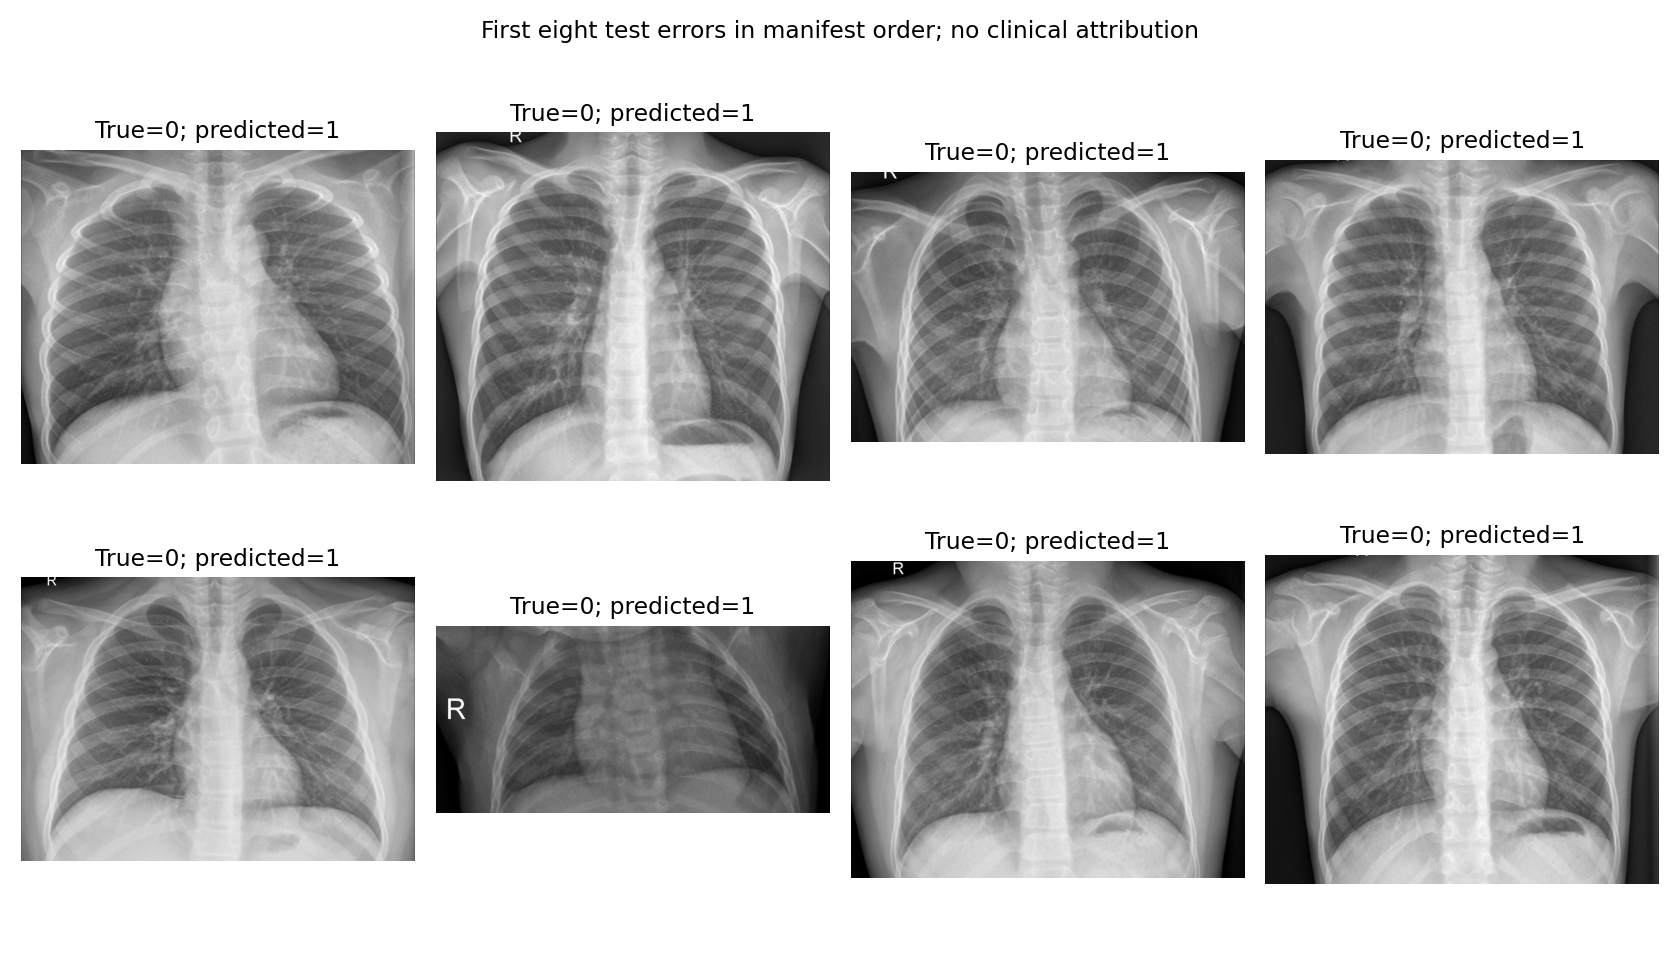

In [14]:
predictions=pd.read_csv(out/'results/test_predictions.csv')
errors=predictions[predictions.target!=predictions.prediction]
print('Test errors:',len(errors))
display(errors.head(8))
error_image=FIGURE_DIR/'error_examples.png'
if error_image.exists(): display(NotebookImage(filename=str(error_image)))

## 15. Save the execution environment

Record package versions and configuration to make the experiment reviewable. Compatible dependency ranges are provided in requirements.txt.

In [15]:
save_json({'seed':SEED,'python':platform.python_version(),'packages':{p:importlib.metadata.version(p) for p in ['numpy','pandas','Pillow','scikit-learn','matplotlib','joblib']}},out/'results/run_environment.json')
print('Saved model:',out/'models/best_model.joblib')
print('Saved evaluation:',out/'results/final_evaluation.json')

Saved model: /Users/ravichandrashinde/Chest-Xray-Pneumonia-ML/models/best_model.joblib
Saved evaluation: /Users/ravichandrashinde/Chest-Xray-Pneumonia-ML/results/final_evaluation.json


## 16. Interpret the results and limitations

Compare CV balanced accuracy with held-out test balanced accuracy. Discuss the measured recall/specificity tradeoff and whether the OOF F1 threshold actually improved test F1. The fixed-C ablation measures the added value of texture and scaling on development only.

The existing run selected logistic regression. It achieved high test ROC-AUC but substantially lower specificity and balanced accuracy than the development estimates. This is a limitation to explain, not hide. Filename proxies cannot certify patient independence. The data is pediatric and single-source; acquisition artifacts and near duplicates can remain. Confidence intervals are conditional on this trained model and cannot establish external generalization. This student benchmark is not clinically validated.

For the literature review and full theory, see the companion all-in-one Phase 1 notebook and `report/phase1_report.md`. [Kermany et al.](https://doi.org/10.1016/j.cell.2018.02.010), [Cortes & Vapnik](https://doi.org/10.1007/BF00994018), and [Zech et al.](https://doi.org/10.1371/journal.pmed.1002683) motivate the task, margin-based model and external-validation caveat.